## XAG329A2 – Self-Improving AI Agents – Part 2 Final Assignment

In this assignment, we will go over basic techniques to scale test-time compute and self-improve. 

The assignment will have 5 parts (**50 points** total):

1. Zero-shot Evaluation (10 points)
2. Majority Voting (10 points)
3. Best-of-N with a Generative Reward Model (10 points)
4. Self-Improvement with Feedback (16 points)
5. Evaluation summaries (4 points)

An optional Analysis and Discussion section at the end is ungraded.





In [1]:
%load_ext autoreload
%autoreload 2

## Importing the relevant tools.
## Make sure you installed this package with the instructions in README.md
import os
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv

from xag329a_a2.tasks import AIME25
from xag329a_a2.methods import get_sampler, get_verifier

# Load environment variables from .env at the repo root (walks up from the notebook cwd).
# Refer README.md for more details. Copy `.env.example` to `.env` and add your tokens.
load_dotenv(find_dotenv())

# Configuration
HF_TOKEN = os.getenv("HUGGINGFACE_HUB_TOKEN")

You can set `DEBUG_MODE` to be `True` when developing. Change to `False` for final results.

In [2]:
DEBUG_MODE = False  # Set to True when developing, False for final results

###  Dataset: AIME25
We will work with the AIME25 dataset from [Hugging Face](https://huggingface.co/datasets/math-ai/aime25).
This dataset contains 30 challenging mathematical problems from the American Invitational Mathematics Examination (AIME).
These problems are significantly more difficult than typical high school math problems and require advanced problem-solving techniques.
<br>
First, let's get familiar with the dataset.

In [3]:
from IPython.display import Markdown, display

aime25 = AIME25(hf_token=HF_TOKEN)
problems = aime25.get_problems(debug_mode=DEBUG_MODE)
system_prompt = aime25.get_system_prompt()

# Each problem is a dictionary with a "problem", "answer", and "id"
print(f"Loaded {len(problems)} AIME25 problems")
print("Problem (raw):", problems[0]["problem"])
print("\nProblem (math rendered):")
display(Markdown(problems[0]["problem"]))
print("answer:", problems[0]["answer"])


Loaded 30 AIME25 problems
Problem (raw): Suppose $\triangle ABC$ has angles $\angle BAC = 84^\circ, \angle ABC=60^\circ,$ and $\angle ACB = 36^\circ.$ Let $D, E,$ and $F$ be the midpoints of sides $\overline{BC}, \overline{AC},$ and $\overline{AB},$ respectively. The circumcircle of $	riangle DEF$ intersects $\overline{BD}, \overline{AE},$ and $\overline{AF}$ at points $G, H,$ and $J,$ respectively. The points $G, D, E, H, J,$ and $F$ divide the circumcircle of $\triangle DEF$ into six minor arcs, as shown. Find $\overarc{DE}+2\cdot \overarc{HJ} + 3\cdot \overarc{FG},$ where the arcs are measured in degrees.[asy] import olympiad; size(6cm); defaultpen(fontsize(10pt)); pair B = (0, 0), A = (Cos(60), Sin(60)), C = (Cos(60)+Sin(60)/Tan(36), 0), D = midpoint(B--C), E = midpoint(A--C), F = midpoint(A--B); guide circ = circumcircle(D, E, F); pair G = intersectionpoint(B--D, circ), J = intersectionpoints(A--F, circ)[0], H = intersectionpoints(A--E, circ)[0]; draw(B--A--C--cycle); draw(D--E--F

Suppose $\triangle ABC$ has angles $\angle BAC = 84^\circ, \angle ABC=60^\circ,$ and $\angle ACB = 36^\circ.$ Let $D, E,$ and $F$ be the midpoints of sides $\overline{BC}, \overline{AC},$ and $\overline{AB},$ respectively. The circumcircle of $	riangle DEF$ intersects $\overline{BD}, \overline{AE},$ and $\overline{AF}$ at points $G, H,$ and $J,$ respectively. The points $G, D, E, H, J,$ and $F$ divide the circumcircle of $\triangle DEF$ into six minor arcs, as shown. Find $\overarc{DE}+2\cdot \overarc{HJ} + 3\cdot \overarc{FG},$ where the arcs are measured in degrees.[asy] import olympiad; size(6cm); defaultpen(fontsize(10pt)); pair B = (0, 0), A = (Cos(60), Sin(60)), C = (Cos(60)+Sin(60)/Tan(36), 0), D = midpoint(B--C), E = midpoint(A--C), F = midpoint(A--B); guide circ = circumcircle(D, E, F); pair G = intersectionpoint(B--D, circ), J = intersectionpoints(A--F, circ)[0], H = intersectionpoints(A--E, circ)[0]; draw(B--A--C--cycle); draw(D--E--F--cycle); draw(circ);  dot(A);dot(B);dot(C);dot(D);dot(E);dot(F);dot(G);dot(H);dot(J); label("$A$", A, (0, .8)); label("$B$", B, (-.8, -.8)); label("$C$", C, (.8, -.8)); label("$D$", D, (0, -.8)); label("$E$", E, (.8, .2)); label("$F$", F, (-.8, .2)); label("$G$", G, (0, .8)); label("$H$", H, (-.2, -1));label("$J$", J, (.2, -.8)); [/asy]

answer: 336


Here, each problem is a dictionary with a `problem` and an `answer`. 
<br>
`problem` is the statement of the mathematical question, and `answer` is the correct answer to the question. Importantly, this is not a multiple-choice question, so the answer can often be a mathematical expression.


### Model API config

We will use open-source language models through [OpenRouter](https://openrouter.ai/). See `README.md` for how to get API keys and add them to your `.env` file.

OpenRouter provides a single API to many open-source models hosted by different providers, so you do not need to set up a dedicated server. Model availability can change over time; if you cannot access a model used in this notebook, please reach out to the teaching staff.

In [4]:
if not os.getenv("OPENROUTER_API_KEY"):
    raise ValueError(
        "OPENROUTER_API_KEY is not set. "
        "Copy .env.example to .env, add your OpenRouter API key "
        "(see README.md), then re-run the imports cell so load_dotenv() runs."
    )
print("OPENROUTER_API_KEY is set.")


OPENROUTER_API_KEY is set.


### Model config

In this assignment, we will use the `Qwen3-Next-80B-A3B-Instruct` model from Qwen, accessed via OpenRouter.

Model page: https://openrouter.ai/qwen/qwen3-next-80b-a3b-instruct


In [5]:
model = "openrouter/qwen/qwen3-next-80b-a3b-instruct"

print(f"Using model: {model}")


Using model: openrouter/qwen/qwen3-next-80b-a3b-instruct


###  Useful tools
To help you implement the techniques we will cover in this assignment, we implemented a few useful methods for you under `xag329a_a2.methods`. We recommend you look through this function, and later fucntions we provide, to understand the capabilities of how they can be used for the assignment!

In [6]:
# let's check system prompt and temperature
# the higher the temperature, the more creative the model is
# to sample multiple responses, we need to set temperature > 0
temperature=0.7

print(f"Temperature: {temperature}")
print(f"\nSystem prompt:\n{system_prompt}")


Temperature: 0.7

System prompt:
You are an expert mathematician specializing in competition mathematics. 
Solve the given AIME (American Invitational Mathematics Examination) problem step by step. 
These problems require advanced mathematical reasoning and creative problem-solving techniques.

Guidelines:
1. Think carefully about the problem structure and what is being asked
2. Use appropriate mathematical techniques (algebra, geometry, number theory, combinatorics, etc.)
3. Show all your work clearly
4. Provide a complete solution with proper reasoning
5. Express your final answer as requested in the problem

Format your response as:
Problem: [restate the problem]
Solution: [step-by-step solution]
Final Answer: [your answer]


In [7]:
# We implement a few useful methods for you under `xag329a_a2.methods`. 

# First, the simple multiple sampler.
# This method returns a list of lists, where for each prompt that is passed as an input, we return a list of responses.
# You will use this method as the basis of the techniques we will implement.
# See the below example where we sample 3 responses from model that we set with a temperature of 0.7.

method = get_sampler(method="sample_multiple", model=model, temperature=temperature, system_prompt=system_prompt)
prompts = ["What language model are you based on?"]
responses = method(prompts)
print("\n".join(responses[0]))


Processing requests:   0%|          | 0/3 [00:00<?, ?it/s]

Processing requests:  33%|███▎      | 1/3 [00:01<00:03,  1.86s/it]

Processing requests: 100%|██████████| 3/3 [00:01<00:00,  1.58it/s]

I am based on the Qwen language model, developed by Alibaba Cloud's Tongyi Lab. I am designed to assist with a wide range of tasks, including answering questions, generating text, solving mathematical problems, and more. If you have any questions or need help, feel free to ask!
I am based on the Qwen language model, developed by Alibaba Cloud's Tongyi Lab. I am designed to assist with a wide range of tasks, including answering questions, generating text, solving mathematical problems, and more. Let me know how I can help you!
I am based on the Qwen language model, a large-scale language model independently developed by Alibaba Group's Tongyi Lab. I am designed to answer questions, create text, perform logical reasoning, programming, and more. If you have any questions or need assistance, feel free to ask me anytime!


### Testing on a single problem

In [8]:
# You can use this method function to get predictions for a given problem.
# We get our first prediction from the method.
# Let's get three predictions for the first problem, and read them out.
problem_prompts = [problems[0]["problem"]]
predictions = method(problem_prompts)[0]
for i in range(len(predictions)):
    print(f"\nPrediction {i+1}:\n{predictions[i]}")
    print("-"*100)


Processing requests:   0%|          | 0/3 [00:00<?, ?it/s]

Processing requests:  33%|███▎      | 1/3 [00:22<00:44, 22.15s/it]

Processing requests: 100%|██████████| 3/3 [00:22<00:00,  5.90s/it]

Processing requests: 100%|██████████| 3/3 [00:22<00:00,  7.52s/it]


Prediction 1:
We are given triangle $ \triangle ABC $ with angles:

- $ \angle BAC = 84^\circ $
- $ \angle ABC = 60^\circ $
- $ \angle ACB = 36^\circ $

Let $ D, E, F $ be the **midpoints** of sides $ BC, AC, AB $, respectively. So $ \triangle DEF $ is the **medial triangle** of $ \triangle ABC $.

We are told that the **circumcircle of $ \triangle DEF $** intersects:

- $ \overline{BD} $ at $ G $ (other than $ D $),
- $ \overline{AE} $ at $ H $ (other than $ E $),
- $ \overline{AF} $ at $ J $ (other than $ F $).

Then, the circle is divided into six minor arcs by the points $ G, D, E, H, J, F $, in that cyclic order (as shown in the diagram).

We are to compute:

$$
\overarc{DE} + 2 \cdot \overarc{HJ} + 3 \cdot \overarc{FG}
$$

where all arcs are measured in degrees along the circumcircle of $ \triangle DEF $.

---

### Step 1: Properties of the medial triangle

In any triangle, the medial triangle $ \triangle DEF $ (formed by joining midpoints) has the following properties:

- Each 

### Verifier

In [9]:
# We give you a verifier tool for the AIME25 dataset.
# The verifier for AIME25 is a simple tool that checks if the prediction is correct.
# Internally, it parses the prediction and the answer and compares the final mathematical expression.
# Importantly, the verifier is not perfect due to parsing challenges. 
# We mostly re-use the Qwen verifier based on the [Qwen-2.5 MATH repository](https://github.com/QwenLM/Qwen2.5-Math/tree/main/evaluation).
# If you can be nerdsniped into writing a better verifier, we'd love to see it!

# Let's test the predictions we got for the first problem that we have.
verifier = get_verifier("aime25")

print("Correct answer: ", problems[0]["answer"])
for prediction in predictions:
    print("Last line of the prediction: ", prediction.split("\n\n")[-1])
    print("Is correct: ", verifier.verify(prediction, problems[0]["answer"]))

Correct answer:  336
Last line of the prediction:  - $ B = (0, 0) $
- $ C = (c
Is correct:  0
Last line of the prediction:  
Is correct:  0
Last line of the prediction:  -
Is correct:  0


## Your turn!

### 1- Evaluating zero-shot predictions (10 points)

First, we will evaluate the accuracy of the predictions with a single sample, without using any test-time compute techniques. <br>
You will only need to use the `method` we defined above and the `verifier` to compute the accuracy.

During development, set `DEBUG_MODE=True` (at the top of the notebook) to use only 5 problems. For your final run, set `DEBUG_MODE=False` to evaluate the full problem set.

Deliverable: 
- Write your code in the section specified by `TODO: YOUR CODE STARTS HERE` and `TODO: YOUR CODE ENDS HERE`.
- Report the accuracy of the predictions below by running the following cells.
- A zero_shot_correctness of type List[int] that will be used later to compare results

In [10]:
def evaluate_zero_shot(method, test_problems, verifier):
    """
    Run zero-shot evaluation.

    Returns
    -------
    zero_shot_correctness : list
        Per-problem correctness (1/0 or True/False)
    all_responses_list : list[list[str]]
        Sampler outputs, one inner list per problem
    """
    zero_shot_correctness = []
    all_responses_list = []

    # Hints:
    # 1. Build a list of prompt strings from `test_problems` (use each problem's `"problem"` field).
    # 2. Call `method(prompts)` to get `all_responses_list`. Each item is a list of sampled responses
    #    (here `n_samples=1`, so each inner list should have length 1).
    # 3. Loop over `zip(all_responses_list, test_problems)`. For each pair:
    #    - Take the single response string (e.g. `prediction[0]`).
    #    - Use `verifier.verify(response, test_problem["answer"])` and append the result
    #      (True/False or 1/0) to `zero_shot_correctness`.
    # 4. (Optional) Print part of the response to sanity-check formatting.

    ### TODO: YOUR CODE STARTS HERE
    prompts = [test_problem["problem"] for test_problem in test_problems]
    all_responses_list = method(prompts)
    for prediction, test_problem in zip(all_responses_list, test_problems):
        response = prediction[0]
        zero_shot_correctness.append(int(verifier.verify(response, test_problem["answer"])))
    ### TODO: YOUR CODE ENDS HERE
    return zero_shot_correctness, all_responses_list


The following cell will test your code. Please make sure to pass the test before proceeding.


In [11]:
from xag329a_a2.tests.test import test_evaluate_zero_shot

test_evaluate_zero_shot(evaluate_zero_shot)


No errors detected for `evaluate_zero_shot`


In [12]:
# Run the zero-shot evaluation with the real sampler (uses LLM API calls).
method = get_sampler(
    method="sample_multiple",
    model=model,
    temperature=temperature,
    n_samples=1,
    system_prompt=system_prompt,
)
test_problems = problems
zero_shot_correctness, all_responses_list = evaluate_zero_shot(
    method, test_problems, verifier
)
### Report the accuracy of the predictions below.
import json

zero_shot_summary = {
    "section": "zero_shot_eval",
    "accuracy": sum(zero_shot_correctness) / len(zero_shot_correctness),
    "correct": int(sum(zero_shot_correctness)),
    "total": len(zero_shot_correctness),
}
print(json.dumps(zero_shot_summary, indent=2))


Processing requests:   0%|          | 0/30 [00:00<?, ?it/s]

Processing requests:   3%|▎         | 1/30 [00:27<13:26, 27.80s/it]

Processing requests:  10%|█         | 3/30 [00:28<03:23,  7.55s/it]

Processing requests:  17%|█▋        | 5/30 [00:31<01:50,  4.43s/it]

Processing requests:  70%|███████   | 21/30 [00:32<00:06,  1.50it/s]

Processing requests: 100%|██████████| 30/30 [00:32<00:00,  1.07s/it]

{
  "section": "zero_shot_eval",
  "accuracy": 0.4,
  "correct": 12,
  "total": 30
}


In [13]:
# OPTIONAL, save all_responses_list for analysis
import json

# Save all_responses_list to JSON file
with open('zero-shot-all_responses_list.json', 'w') as f:
    json.dump(all_responses_list, f, indent=2)

print(f"Saved {len(all_responses_list)} all_responses_list to zero-shot-all_responses_list.json")

Saved 30 all_responses_list to zero-shot-all_responses_list.json


### 2- Majority Voting (10 points)

Here we will implement our first test-time compute technique, majority voting, as described in [this paper](https://arxiv.org/abs/2408.03314) or [this earlier paper](https://arxiv.org/abs/2203.11171). In particular,
- You will sample multiple (in this case, 16) responses for each problem.
- You will then take the majority vote as the prediction. The voting will be performed per each normalized expression (i.e., given the entire solution, we will parse the final numerical expression and perform the voting on that). We provide utility functions to do this.
- You will then evaluate the prediction against the ground truth.


During development, set `DEBUG_MODE=True` (at the top of the notebook) to use only 5 problems. For your final run, set `DEBUG_MODE=False` to evaluate the full problem set.


Deliverable: 
- Write your code in the section specified by `TODO: YOUR CODE STARTS HERE` and `TODO: YOUR CODE ENDS HERE`.
- Report the accuracy of the predictions below by running the following cells.

In [14]:
## 2.1 - Implementing majority voting.
from typing import List, Union
from xag329a_a2.methods.simple_samplers import SampleMultiple
from xag329a_a2.tasks.math_utils import (
    strip_string,
    extract_answer,
)

class MajorityVoting:
    """
    A class that implements majority voting strategy using multiple samples.
    It generates multiple responses for each prompt and selects the most common answer.
    """

    def __init__(
        self,
        model: str,
        system_prompt: str = None,
        n_samples: int = 5,
        temperature: float = 0.7,
        max_workers: int = 16
    ):
        """
        Initialize the majority voting method.

        Args:
            model (str): The name of the model to use
            system_prompt (str, optional): System prompt to use for the model
            n_samples (int, optional): Number of samples to generate per prompt. Defaults to 5.
            temperature (float, optional): Temperature for sampling. Defaults to 0.7.
        """
        self.sampler = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=n_samples,
            temperature=temperature,
            max_workers=max_workers
        )

    def _parse_answer(self, response: str) -> str:
        return strip_string(extract_answer(response, "math"))

    def _get_majority_answer(self, responses: List[str]) -> str:
        """
        Determine the majority answer from a list of responses using a simple counter.

        Args:
            responses (List[str]): List of model responses

        Returns:
            str: The most common answer
        """
        assert isinstance(responses, list), "Responses must be a list"
        assert all(
            isinstance(r, str) for r in responses
        ), "All responses must be strings"

        majority_answer = None
        ## Implement the majority voting logic here.
        ## Feel free to use the `_parse_answer` method we implemented for you.

        # Hints:
        # 1. Parse each response into a normalized answer string with `self._parse_answer(response)`.
        # 2. Count how often each unique answer appears (e.g. a dict counter, or `collections.Counter`).
        # 3. Skip empty / failed parses so they do not affect the vote.
        # 4. Choose the answer with the highest count as `majority_answer`.
        # 5. If there are no valid answers, return an empty string `""`.
        ### TODO: YOUR CODE STARTS HERE
        from collections import Counter

        parsed = [self._parse_answer(response) for response in responses]
        counts = Counter(answer for answer in parsed if answer)
        # Counter.most_common breaks ties by first occurrence, which keeps the vote deterministic.
        majority_answer = counts.most_common(1)[0][0] if counts else ""
        ### TODO: YOUR CODE ENDS HERE
        return majority_answer

    def __call__(self, prompts: Union[str, List[str]], majority_voting_levels: List[int] = [1, 2, 4, 8, 16]) -> List[str]:
        """
        Execute majority voting on given prompt(s).

        Args:
            prompts (str or List[str]): The input prompt(s) to process

        Returns:
            List[List[str]]: For each majority voting level, we return the majority answer.
        """
        
        majority_answers = []
        responses = self.sampler(prompts)
        for majority_voting_level in majority_voting_levels:
            majority_answers.append([self._get_majority_answer(responses[i][:majority_voting_level]) for i in range(len(responses))])
        return majority_answers

The following cell will test your code. Please make sure to pass the test before proceeding.


In [15]:
from xag329a_a2.tests.test import test_get_majority_answer

mv_for_test = MajorityVoting(
    model=model,
    n_samples=4,
    temperature=temperature,
    system_prompt=system_prompt,
)
test_get_majority_answer(mv_for_test._get_majority_answer)


No errors detected for `_get_majority_answer`


In [16]:
method = MajorityVoting(
    model=model,
    n_samples=16,
    temperature=temperature,
    system_prompt=system_prompt,
    max_workers=32
)

In [17]:
## Do not modify the code below; it is used to evaluate the accuracy of the predictions across different majority voting budgets.

test_problems = problems

total = len(test_problems)
prompts = [problem["problem"] for problem in test_problems]

majority_voting_levels = [1, 2, 4, 8, 16]
# Get all responses at once (this uses internal threading)
all_responses_list = method(prompts)


majority_voting_accuracies = []
for responses_list, majority_voting_level in zip(all_responses_list, majority_voting_levels):
    correct = 0
    
    for prediction, problem in zip(responses_list, test_problems):
        # We do not re-normalize the prediction here, as we already normalized it in the majority voting step.
        # To do so, we set the normalize_prediction flag to False.
        if verifier.verify(prediction, problem["answer"], normalize_prediction=False):
            correct += 1
        
    accuracy = correct / len(test_problems)
    majority_voting_accuracies.append(accuracy)

import json

majority_voting_summary = {
    "section": "majority_voting_eval",
    "majority_voting_levels": majority_voting_levels,
    "accuracies": majority_voting_accuracies,
}
print(json.dumps(majority_voting_summary, indent=2))


Processing requests:   0%|          | 0/480 [00:00<?, ?it/s]

Processing requests:   7%|▋         | 33/480 [00:06<01:21,  5.45it/s]

Processing requests:   7%|▋         | 35/480 [00:06<01:17,  5.76it/s]

Processing requests:   8%|▊         | 37/480 [00:13<03:50,  1.92it/s]

Processing requests:   9%|▉         | 44/480 [00:13<02:34,  2.82it/s]

...

Processing requests:  94%|█████████▍| 451/480 [07:33<00:31,  1.07s/it]

Processing requests:  97%|█████████▋| 466/480 [07:34<00:06,  2.11it/s]

Processing requests:  99%|█████████▉| 477/480 [07:36<00:01,  2.68it/s]

Processing requests: 100%|██████████| 480/480 [07:36<00:00,  1.05it/s]

{
  "section": "majority_voting_eval",
  "majority_voting_levels": [
    1,
    2,
    4,
    8,
    16
  ],
  "accuracies": [
    0.3333333333333333,
    0.3333333333333333,
    0.36666666666666664,
    0.4,
    0.4666666666666667
  ]
}


Saved figure to majority-voting.png


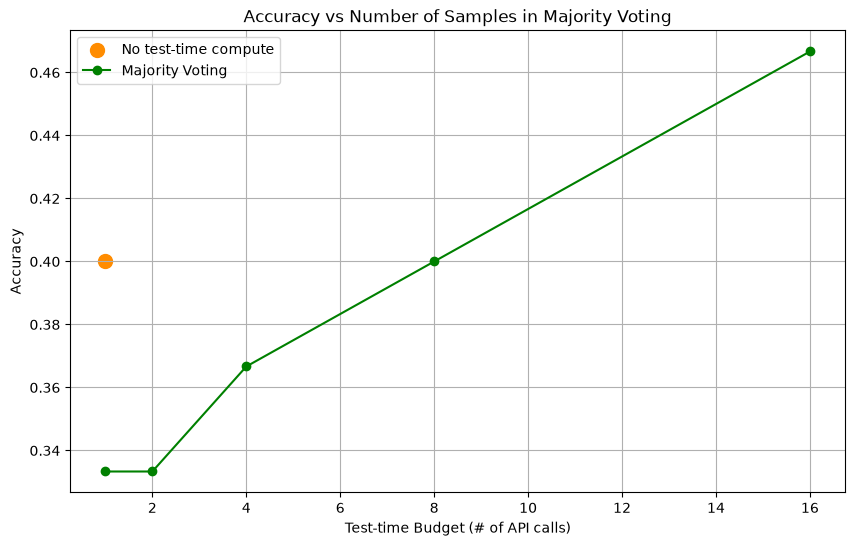

In [18]:
plt.figure(figsize=(10, 6))
plt.scatter([1], [sum(zero_shot_correctness) / len(zero_shot_correctness)], s=100, color="darkorange", marker="o", label='No test-time compute')
plt.plot(majority_voting_levels, majority_voting_accuracies, marker='o', color="green", label='Majority Voting')
plt.xlabel('Test-time Budget (# of API calls)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Number of Samples in Majority Voting')
plt.legend()
plt.grid(True)
plt.savefig('majority-voting.png', dpi=300, bbox_inches='tight')
print("Saved figure to majority-voting.png")
plt.show()

In [19]:
# OPTIONAL, save all_responses_list for analysis
import json

# Save all_responses_list to JSON file
with open('majority-voting-all_responses_list.json', 'w') as f:
    json.dump(all_responses_list, f, indent=2)

print(f"Saved {len(all_responses_list)} all_responses_list to majority-voting-all_responses_list.json")

Saved 5 all_responses_list to majority-voting-all_responses_list.json


### 3- Best-of-N with a Generative Reward Model (10 points)

Here we will implement our second test-time compute technique, best-of-N with a generative reward model. In particular,
- You will sample multiple (in this case, 16) responses for each problem.
- You will then use an LLM to aggregate these responses and select the best answer. This is akin to best-of-N with a reward model as in [the paper](https://arxiv.org/abs/2408.03314), but we use an LLM as a judge instead of a discriminative reward model. This is sometimes referred to [Generative Verifiers](https://arxiv.org/abs/2408.15240) or [Generative Reward Models](https://arxiv.org/abs/2410.12832).
- You will then verify the prediction against the ground truth.
- (Extra challenge) We give a default prompt for the generative reward model. If you can improve the existing prompt and improve the accuracy of the technique compared to the numbers you get otherwise, we encourage to try. There is not an absolute number to beat, but ideally you observe +5% improvement over the default prompt.


During development, set `DEBUG_MODE=True` (at the top of the notebook) to use only 5 problems. For your final run, set `DEBUG_MODE=False` to evaluate the full problem set.



Deliverables:
- Write your code in the section specified by `TODO: YOUR CODE STARTS HERE` and `TODO: YOUR CODE ENDS HERE`.
- Report the accuracy of the predictions below by running the following cells.

In [20]:
class LLMVoting:
    """
    A class that uses an LLM to aggregate multiple responses and select the best answer.
    It generates multiple responses for each prompt and uses another LLM call to choose the best answer.
    """

    def __init__(
        self,
        model: str,
        system_prompt: str = None,
        n_samples: int = 5,
        temperature: float = 0.7,
        max_workers: int = 16
    ):
        """
        Initialize the LLM voting method.

        Args:
            model (str): The name of the model to use
            system_prompt (str, optional): System prompt to use for the model
            n_samples (int, optional): Number of samples to generate per prompt. Defaults to 5.
            temperature (float, optional): Temperature for sampling. Defaults to 0.7.
        """
        self.sampler = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=n_samples,
            temperature=temperature,
            max_workers=max_workers
        )
        
        self.aggregator = SampleMultiple(
            model=model,
            system_prompt=system_prompt + """\n\nYou are a mathematical expert. You will be shown multiple solutions to a math problem.
Your task is to analyze these solutions and select the most likely correct answer.""",
            n_samples=1,
            temperature=0, # temperature is 0 for deterministic output
            max_workers=max_workers
        )

    def _create_aggregation_prompts(self, problems: List[str], all_responses: List[List[str]]) -> List[str]:
        """
        Create prompts for aggregation in parallel.
        
        Args:
            problems (List[str]): List of original problems
            all_responses (List[List[str]]): List of response lists for each problem
            
        Returns:
            List[str]: List of prompts for the aggregator
        """
        return [
            f"""Here is a math problem:
{problem}

I have received multiple solutions. Here they are:

{chr(10).join(f'Solution {i+1}:{chr(10)}{r}' for i, r in enumerate(responses))}

Based on these solutions, restate the solution here that you think is most likely correct."""
            for problem, responses in zip(problems, all_responses)
        ]

    def __call__(self, prompts: Union[str, List[str]]) -> List[List[str]]:
        """
        Execute LLM-based voting on given prompt(s).

        Args:
            prompts (str or List[str]): The input prompt(s) to process

        Returns:
            List[List[str]]: The chosen answer(s) and all responses
        """
        best_of_n_response = None

        # Get multiple samples for each prompt
        # Hints (~4 lines):
        # 1. Sample with `self.sampler(prompts)`.
        # 2. Build aggregation prompts with `self._create_aggregation_prompts(...)`.
        # 3. Call `self.aggregator(...)` and return its result.

        ### TODO: YOUR CODE STARTS HERE
        all_responses = self.sampler(prompts)
        problems_list = [prompts] if isinstance(prompts, str) else prompts
        aggregation_prompts = self._create_aggregation_prompts(problems_list, all_responses)
        best_of_n_response = self.aggregator(aggregation_prompts)
        ### TODO: YOUR CODE ENDS HERE
        return best_of_n_response

The following cell will test your code. Please make sure to pass the test before proceeding.


In [21]:
from xag329a_a2.tests.test import test_llm_voting_call

lv_for_test = LLMVoting(
    model=model,
    n_samples=2,
    temperature=temperature,
    system_prompt=system_prompt,
)
test_llm_voting_call(lv_for_test)


No errors detected for `LLMVoting.__call__`


In [22]:
# Implement and test LLM Voting
llm_method = LLMVoting(
    model=model,
    n_samples=16,
    temperature=0.7,
    system_prompt=system_prompt,
    max_workers=32
)

# Test LLM voting on the same problems
test_problems = problems
prompts = [problem["problem"] for problem in test_problems]

# Get LLM voting predictions
llm_predictions = llm_method(prompts)

# Calculate LLM voting accuracy
correct_llm_voting = 0
total_llm_voting = len(test_problems)

for prediction, problem in zip(llm_predictions, test_problems):
    if verifier.verify(prediction[0], problem["answer"]):
        correct_llm_voting += 1

llm_voting_accuracy = correct_llm_voting / total_llm_voting

import json

llm_voting_summary = {
    "section": "llm_voting_eval",
    "accuracy": llm_voting_accuracy,
    "correct": correct_llm_voting,
    "total": total_llm_voting,
}
print(json.dumps(llm_voting_summary, indent=2))


Processing requests:   0%|          | 0/480 [00:00<?, ?it/s]

Processing requests:   7%|▋         | 35/480 [00:24<05:10,  1.43it/s]

Processing requests:   8%|▊         | 40/480 [00:24<04:21,  1.68it/s]

Processing requests:  10%|█         | 48/480 [00:27<03:45,  1.92it/s]

Processing requests:  14%|█▎        | 65/480 [00:49<05:58,  1.16it/s]

...

Processing requests:   3%|▎         | 1/30 [00:56<27:11, 56.27s/it]

Processing requests:  10%|█         | 3/30 [01:10<08:55, 19.84s/it]

Processing requests:  27%|██▋       | 8/30 [01:12<02:06,  5.74s/it]

Processing requests: 100%|██████████| 30/30 [01:12<00:00,  2.42s/it]

{
  "section": "llm_voting_eval",
  "accuracy": 0.6333333333333333,
  "correct": 19,
  "total": 30
}


In [23]:
# OPTIONAL, save llm_predictions for analysis
import json

# Save llm_predictions to JSON file
with open('best-of-n-all_responses_list.json', 'w') as f:
    json.dump(llm_predictions, f, indent=2)

print(f"Saved {len(llm_predictions)} llm_predictions to best-of-n-all_responses_list.json")

Saved 30 llm_predictions to best-of-n-all_responses_list.json




### 4- Iterative Self-Improvement Using Execution Feedback (16 points)

This section implements a self-improvement system inspired by the RLEF (Reinforcement Learning with Execution Feedback) approach described in [Gehring et al., 2024](https://arxiv.org/pdf/2410.02089). The system samples an initial solution, critiques it, and then regenerates an improved solution using the feedback.

**Key Innovation**: Instead of generating multiple independent samples, we use a single sample followed by targeted feedback and regeneration. This mimics how humans learn from mistakes and iteratively improve their solutions.

**Process Overview**:
1. **Initial Generation**: Generate one solution to the problem
2. **Critique Phase**: Analyze the solution for errors and provide constructive feedback
3. **Regeneration Phase**: Generate a new solution incorporating the feedback
4. **Evaluation**: Compare original vs. improved solution accuracy

**Requirements:**
- Implement a critique system using a single model for feedback generation
- Implement solution regeneration based on critiques
- Test on all 30 problems from the AIME25 dataset
- Compare accuracy before and after self-improvement
- Analyze the effectiveness of the feedback-based approach

During development, set `DEBUG_MODE=True` (at the top of the notebook) to use only 5 problems. For your final run, set `DEBUG_MODE=False` to evaluate the full problem set.

Here are example prompts that can be helpful for `SelfImprovementSystem`. You are welcome to modify them for your runs.

```python
# criticizing solution
        prompt = f"""
Problem: {problem}

Solution: {solution}

Please analyze this solution and provide constructive feedback. Focus on identifying errors, gaps, or areas for improvement.
"""

# regenerating solution
        prompt = f"""
Problem: {problem}

Previous solution: {original_solution}

Feedback on the previous solution: {feedback}

Please provide an improved solution that addresses the feedback. Make sure to:
1. Address the specific issues mentioned in the feedback
2. Provide clear reasoning for your approach
3. Ensure mathematical accuracy
4. Be complete and well-explained

Improved Solution:
"""
```



In [24]:
class SelfImprovementSystem:
    """
    A class that implements classic RLEF (Reinforcement Learning from Execution Feedback).
    Uses only model we configured for both generation and critique.
    """

    def __init__(self, model: str, system_prompt: str = None, temperature: float = 0.7, max_workers: int = 8):
        # Main generator for initial solutions
        self.generator = SampleMultiple(
            model=model,
            system_prompt=system_prompt,
            n_samples=1,
            temperature=temperature,
            max_workers=max_workers
        )
        
        # Critic for providing feedback
        critic_system_prompt = """You are an expert mathematical critic. Your job is to analyze mathematical solutions and provide constructive feedback.

When given a problem and its solution, analyze it for:
1. Logical errors and reasoning gaps
2. Mathematical mistakes and calculation errors
3. Conceptual misunderstandings
4. Missing steps or incomplete reasoning

Provide specific, actionable feedback that can help improve the solution. If the solution is correct, acknowledge that but still suggest potential improvements or alternative approaches.

Format your feedback as:
- **Issues Found:** [List specific problems]
- **Suggestions:** [How to fix the issues]
- **Overall Assessment:** [Brief summary]"""

        self.critic = SampleMultiple(
            model=model,
            system_prompt=critic_system_prompt,
            n_samples=1,
            temperature=0.3,  # Lower temperature for more focused critiques
            max_workers=max_workers
        )
        
        # Regenerator for creating improved solutions based on feedback
        regenerator_system_prompt = """You are an expert mathematician who learns from feedback. When given a problem, your previous solution, and feedback about that solution, you should:

1. Carefully analyze the feedback provided
2. Identify the key issues that need to be addressed
3. Generate a new, improved solution that addresses the feedback
4. Ensure your new solution is logically sound and mathematically correct

Always acknowledge the feedback and explain how you've addressed the main issues in your new solution."""

        self.regenerator = SampleMultiple(
            model=model,
            system_prompt=regenerator_system_prompt,
            n_samples=1,
            temperature=temperature,
            max_workers=max_workers
        )

    def _generate_initial_solution(self, problem: str) -> str:
        """Generate the initial solution to a problem."""
        ### TODO: YOUR CODE STARTS HERE
        return self.generator(problem)[0][0]
        ### TODO: YOUR CODE ENDS HERE

    def _critique_solution(self, problem: str, solution: str) -> str:
        """
        Critique a solution and provide feedback.
        
        Args:
            problem (str): The original problem
            solution (str): The solution to critique
            
        Returns:
            str: Feedback about the solution
        """
        # Hint: build a prompt with the problem + solution, then call `self.critic(...)` and return the response text.
        ### TODO: YOUR CODE STARTS HERE
        prompt = (
            f"Problem: {problem}\n\n"
            f"Solution: {solution}\n\n"
            "Please analyze this solution and provide constructive feedback. "
            "Focus on identifying errors, gaps, or areas for improvement. "
            "Recompute the key steps and the final answer independently rather than trusting the solution's arithmetic.\n"
            'End your feedback with exactly one line: "Verdict: CORRECT" if you find no error that changes '
            'the final answer, or "Verdict: INCORRECT" if you do.'
        )
        return self.critic(prompt)[0][0]
        ### TODO: YOUR CODE ENDS HERE

    def _regenerate_solution(self, problem: str, original_solution: str, feedback: str) -> str:
        """
        Generate an improved solution based on feedback.
        
        Args:
            problem (str): The original problem
            original_solution (str): The original solution
            feedback (str): Feedback about the original solution
            
        Returns:
            str: The improved solution
        """
        # Hint: build a prompt with the problem, previous solution, and feedback, then call `self.regenerator(...)` and return the response text.
        ### TODO: YOUR CODE STARTS HERE
        prompt = (
            f"Problem: {problem}\n\n"
            f"Previous solution: {original_solution}\n\n"
            f"Feedback on the previous solution: {feedback}\n\n"
            "Please provide an improved solution that addresses the feedback. Make sure to:\n"
            "1. Address the specific issues mentioned in the feedback\n"
            "2. Provide clear reasoning for your approach\n"
            "3. Ensure mathematical accuracy\n"
            "4. Be complete and well-explained\n"
            "5. If the feedback finds no error that changes the final answer, keep the same final answer "
            "rather than changing it for the sake of change\n"
            "6. End with the final answer written as \\boxed{answer}\n\n"
            "Improved Solution:"
        )
        return self.regenerator(prompt)[0][0]
        ### TODO: YOUR CODE ENDS HERE

    def improve_solution(self, problem: str) -> dict:
        """
        Complete RLEF self-improvement process for a single problem.
        
        Args:
            problem (str): The problem to solve
            
        Returns:
            dict: Results including original solution, feedback, and improved solution
        """
        original_solution, feedback, improved_solution = None, None, None

        # Hints (~3 lines):
        # step 1: generate original solution
        # step 2: critic the solution and get feedback
        # setp 3: regenerate improved solution
        ### TODO: YOUR CODE STARTS HERE
        original_solution = self._generate_initial_solution(problem)
        feedback = self._critique_solution(problem, original_solution)
        improved_solution = self._regenerate_solution(problem, original_solution, feedback)
        ### TODO: YOUR CODE ENDS HERE

        return {
            "problem": problem,
            "original_solution": original_solution,
            "feedback": feedback,
            "improved_solution": improved_solution
        }

    def evaluate_improvement(self, results: dict, correct_answer: str) -> dict:
        """
        Evaluate whether the improved solution is better than the original.
        
        Args:
            results (dict): Results from improve_solution
            correct_answer (str): The correct answer to the problem
            
        Returns:
            dict: Evaluation results including accuracy comparisons
        """
        original_correct, improved_correct, improvement = None, None, None

        # Hints:
        # 1. Use `get_verifier("aime25")` to check the original and improved solutions against `correct_answer`.
        # 2. Set `improvement` to True only when the original was wrong and the improved solution is correct.
        ### TODO: YOUR CODE STARTS HERE
        verifier = get_verifier("aime25")
        original_correct = bool(verifier.verify(results["original_solution"], correct_answer))
        improved_correct = bool(verifier.verify(results["improved_solution"], correct_answer))
        improvement = (not original_correct) and improved_correct
        ### TODO: YOUR CODE ENDS HERE
        return {
            "original_correct": original_correct,
            "improved_correct": improved_correct,
            "improvement": improvement, # bool
            "correct_answer": correct_answer
        } 

The following cell will test your code. Please make sure to pass the test before proceeding.


In [25]:
from xag329a_a2.tests.test import test_self_improvement_system

sis_for_test = SelfImprovementSystem(
    model=model,
    temperature=temperature,
    system_prompt=system_prompt,
)
test_self_improvement_system(sis_for_test)


No errors detected for `SelfImprovementSystem`


In [26]:
# Initialize the Self-Improvement System (RLEF)
# This system uses only model we configured for generation, critique, and regeneration
self_improvement_system = SelfImprovementSystem(
    model=model,
    temperature=0.7,
    system_prompt=system_prompt,
    max_workers=16
)

test_problems_size=len(problems)
test_problems = problems

print(f"Testing RLEF self-improvement system on {test_problems_size} problems...")
print("This will take several minutes as we generate initial solutions, critique them, and regenerate improved solutions.")
print(f"Using only {model} for all steps (generation, critique, regeneration).")
print()

# Store results for analysis
improvement_results = []
original_accuracies = []
improved_accuracies = []

for i, problem in enumerate(test_problems):
    print(f"Processing problem {i+1}/{test_problems_size}...")
    
    # Run the complete RLEF self-improvement process
    result = self_improvement_system.improve_solution(problem["problem"])
    
    # Evaluate the improvement
    evaluation = self_improvement_system.evaluate_improvement(result, problem["answer"])
    
    # Store results
    improvement_results.append({
        "problem_index": i,
        "problem": problem["problem"],
        "correct_answer": problem["answer"],
        "result": result,
        "evaluation": evaluation
    })
    
    original_accuracies.append(evaluation["original_correct"])
    improved_accuracies.append(evaluation["improved_correct"])
    
    # Print progress
    if evaluation["improvement"]:
        print(f"  ✓ Improved from incorrect to correct!")
    elif evaluation["original_correct"] and evaluation["improved_correct"]:
        print(f"  → Both solutions correct")
    elif not evaluation["original_correct"] and not evaluation["improved_correct"]:
        print(f"  → Both solutions incorrect")
    else:
        print(f"  → Regressed from correct to incorrect")

print(f"\nCompleted processing {test_problems_size} problems!")

Testing RLEF self-improvement system on 30 problems...
This will take several minutes as we generate initial solutions, critique them, and regenerate improved solutions.
Using only openrouter/qwen/qwen3-next-80b-a3b-instruct for all steps (generation, critique, regeneration).

Processing problem 1/30...


Processing requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processing requests: 100%|██████████| 1/1 [00:22<00:00, 22.30s/it]

Processing requests: 100%|██████████| 1/1 [00:22<00:00, 22.30s/it]

Processing requests:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processing requests: 100%|██████████| 1/1 [00:10<00:00, 10.07s/it]

Processing requests:   0%|          | 0/1 [00:00<?, ?it/s]

Processing requests: 100%|██████████| 1/1 [00:15<00:00, 15.34s/it]

Processing requests: 100%|██████████| 1/1 [00:15<00:00, 15.34s/it]

  → Both solutions correct

Completed processing 30 problems!


In [27]:
# Analyze the results
print("=== RLEF Self-Improvement Analysis ===")
print()

# Calculate overall accuracies
original_accuracy = sum(original_accuracies) / len(original_accuracies)
improved_accuracy = sum(improved_accuracies) / len(improved_accuracies)
improvement_count = sum(1 for i in range(len(original_accuracies)) 
                       if improved_accuracies[i] and not original_accuracies[i])
regression_count = sum(1 for i in range(len(original_accuracies)) 
                     if original_accuracies[i] and not improved_accuracies[i])

print(f"Original Solution Accuracy: {original_accuracy:.3f} ({sum(original_accuracies)}/{len(original_accuracies)})")
print(f"Improved Solution Accuracy: {improved_accuracy:.3f} ({sum(improved_accuracies)}/{len(improved_accuracies)})")
print(f"Accuracy Improvement: {improved_accuracy - original_accuracy:.3f}")
print(f"Problems Improved: {improvement_count}")
print(f"Problems Regressed: {regression_count}")
print()

# Show detailed examples of improvements
print("=== Detailed Improvement Examples ===")
improvement_examples = [r for r in improvement_results if r["evaluation"]["improvement"]]

if improvement_examples:
    print(f"Found {len(improvement_examples)} successful improvements. Showing first example:")
    example = improvement_examples[0]
    
    print(f"\nProblem: {example['problem']}")
    print(f"Correct Answer: {example['correct_answer']}")
    print(f"\nOriginal Solution:")
    print(example['result']['original_solution'][:500] + "..." if len(example['result']['original_solution']) > 500 else example['result']['original_solution'])
    
    print(f"\nFeedback from {model} Critic:")
    print(example['result']['feedback'][:500] + "..." if len(example['result']['feedback']) > 500 else example['result']['feedback'])
    
    print(f"\nImproved Solution:")
    print(example['result']['improved_solution'][:500] + "..." if len(example['result']['improved_solution']) > 500 else example['result']['improved_solution'])
else:
    print("No successful improvements found in this subset.")

=== RLEF Self-Improvement Analysis ===

Original Solution Accuracy: 0.333 (10/30)
Improved Solution Accuracy: 0.600 (18/30)
Accuracy Improvement: 0.267
Problems Improved: 8
Problems Regressed: 0

=== Detailed Improvement Examples ===
Found 8 successful improvements. Showing first example:

Problem: Let $A_1A_2\dots A_{11}$ be a non-convex $11$-gon such that The area of $A_iA_1A_{i+1}$ is $1$ for each $2 \le i \le 10$, $\cos(\angle A_iA_1A_{i+1})=\frac{12}{13}$ for each $2 \le i \le 10$, The perimeter of $A_1A_2\dots A_{11}$ is $20$. If $A_1A_2+A_1A_{11}$ can be expressed as $\frac{m\sqrt{n}-p}{q}$ for positive integers $m,n,p,q$ with $n$ squarefree and $\gcd(m,p,q)=1$, find $m+n+p+q$.
Correct Answer: 19

Original Solution:
We are given a non-convex 11-gon $A_1A_2\dots A_{11}$ with the following properties:

- For each $2 \le i \le 10$, the area of triangle $A_iA_1A_{i+1}$ is 1.
- For each $2 \le i \le 10$, $\cos(\angle A_iA_1A_{i+1}) = \frac{12}{13}$.
- The **perimeter** of the entire 

In [28]:
# Save improvement_results to JSON file
import json

with open('self-improvement_results.json', 'w') as f:
    json.dump(improvement_results, f, indent=2)

print(f"Saved {len(improvement_results)} improvement results to self-improvement_results.json")

# Also save a summary with just the key metrics
summary = {
    "section": "self_improvement_eval",
    "total_problems": len(improvement_results),
    "original_accuracy": sum(original_accuracies) / len(original_accuracies),
    "improved_accuracy": sum(improved_accuracies) / len(improved_accuracies),
    "improvement_count": sum(1 for i in range(len(original_accuracies)) if improved_accuracies[i] and not original_accuracies[i]),
    "regression_count": sum(1 for i in range(len(original_accuracies)) if original_accuracies[i] and not improved_accuracies[i]),
    "original_accuracies": original_accuracies,
    "improved_accuracies": improved_accuracies,
}

with open('self-improvement_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("Saved summary to self-improvement_summary.json")


Saved 30 improvement results to self-improvement_results.json
{
  "section": "self_improvement_eval",
  "total_problems": 30,
  "original_accuracy": 0.3333333333333333,
  "improved_accuracy": 0.6,
  "improvement_count": 8,
  "regression_count": 0,
  "original_accuracies": [
    false,
    false,
    false,
    false,
    false,
    false,
    true,
    false,
    false,
    true,
    false,
    false,
    false,
    false,
    true,
    false,
    false,
    false,
    true,
    true,
    false,
    false,
    false,
    true,
    true,
    false,
    false,
    true,
    true,
    true
  ],
  "improved_accuracies": [
    false,
    false,
    false,
    true,
    true,
    false,
    true,
    false,
    false,
    true,
    false,
    true,
    false,
    false,
    true,
    false,
    true,
    false,
    true,
    true,
    false,
    true,
    true,
    true,
    true,
    true,
    true,
    true,
    true,
    true
  ]
}
Saved summary to self-improvement_summary.json


## Analysis and Discussion (Optional)

**Optional**: We suggest that you analyze the following tasks based on your experimental results from the previous sections. We provide you an supplementary reflexion note (`optional_question_supplement.md`).

### Performance Comparison Graph

The following graph summarizes the methods you implemented in this assignment. It plots accuracy against test-time budget (# of API calls) for:
1. Zero-shot baseline (1 call)
2. Majority voting across sample sizes `[1, 2, 4, 8, 16]`
3. LLM voting (16 samples + aggregation)
4. Self-improvement / RLEF (3 calls: initial + critique + regeneration)

Run the cell below to generate the comparison from your earlier results.


Saved figure to summary.png


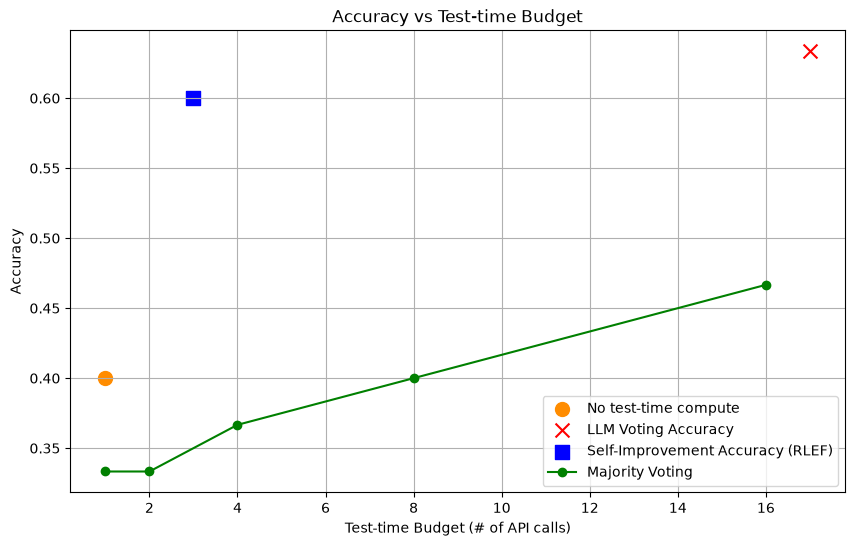

In [29]:
# Performance Comparison Graph (provided)
plt.figure(figsize=(10, 6))
plt.scatter([1], [sum(zero_shot_correctness) / len(zero_shot_correctness)], s=100, color="darkorange", marker="o", label='No test-time compute')

plt.scatter([17], [llm_voting_accuracy], s=100, color="red", marker="x", label='LLM Voting Accuracy')

plt.scatter([3], [sum(improved_accuracies) / len(improved_accuracies)], s=100, color="blue", marker="s", label='Self-Improvement Accuracy (RLEF)')

plt.plot(majority_voting_levels, majority_voting_accuracies, marker='o', color="green", label='Majority Voting')
plt.xlabel('Test-time Budget (# of API calls)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Test-time Budget')
plt.legend()
plt.grid(True)
plt.savefig('summary.png', dpi=300, bbox_inches='tight')
print("Saved figure to summary.png")
plt.show()


## **Task 1: Quantitative Analysis (Optional)**


Based on your experimental results, answer the following specific questions with numerical evidence:

1. **Accuracy Rankings**: List the methods in order of highest to lowest accuracy. Include the actual accuracy values.

**Answer** 


2. **Cost-Effectiveness**: Calculate the accuracy improvement per additional API call for majority voting (from n=1 to n=16) and compare it to self-improvement (3 API calls total). Which method provides better returns on additional compute?

**Answer**


3. **Self-Improvement Analysis**: 
   - What is the accuracy improvement from self-improvement compared to zero-shot?
   - Based on your error category analysis, which error type (logical, mathematical, conceptual, completeness) appears most frequently in incorrect solutions?
   - What percentage of problems showed successful improvement?

**Answer** 


## **Task 2: Method-Specific Insights (Optional)**


Address these specific questions about the methods you implemented:

1. **Majority Voting**: 
   - At what sample size does majority voting show diminishing returns? (Identify the point where accuracy improvement becomes minimal)
   - What is the maximum accuracy achieved by majority voting?

**Answer** 

2. **LLM Voting**: 
   - How does LLM voting accuracy compare to majority voting at n=16?
   - What is the computational cost difference between LLM voting and majority voting at n=16?

**Answer** 



3. **Self-Improvement**:
   - How does the self-improvement approach compare to traditional test-time compute methods?
   - What are the advantages and disadvantages of using feedback-based regeneration vs. multiple independent samples?
   - Based on your results, which error categories seem most important for guiding improvements?

**Answer** 


